In [1]:

from pathlib import Path
import json
import warnings
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
)
from sklearn.calibration import CalibrationDisplay

warnings.filterwarnings("default")

RANDOM_STATE = 42
TARGET = "TARGET"
ID_COLUMN = "SK_ID_CURR"

PROJECT_DIR = Path.cwd()
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
RESULTS_DIR = PROJECT_DIR / "results"
REPORT_DIR = RESULTS_DIR / "final_report"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("FinResilience AI — Notebook 3")
print("Project directory:", PROJECT_DIR.resolve())
print("Artifact directory:", ARTIFACT_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())


FinResilience AI — Notebook 3
Project directory: C:\mini_project
Artifact directory: C:\mini_project\artifacts
Results directory: C:\mini_project\results


In [4]:

REQUIRED_ARTIFACTS = [
    ARTIFACT_DIR / "home_credit_test_LOCKED.csv",
    ARTIFACT_DIR / "home_credit_feature_groups.json",
    ARTIFACT_DIR / "best_group_b_calibrated_model.joblib",
    ARTIFACT_DIR / "model_metadata.json",
]

OPTIONAL_ARTIFACTS = [
    ARTIFACT_DIR / "home_credit_train.csv",
    ARTIFACT_DIR / "home_credit_feature_table.csv",
    ARTIFACT_DIR / "home_credit_audit_columns.csv",
    ARTIFACT_DIR / "all_calibrated_models.joblib",
    RESULTS_DIR / "research_summary.json",
    RESULTS_DIR / "final_report" / "test_performance_metrics.json",
    RESULTS_DIR / "final_report" / "calibration_summary.csv",
]


missing_required = [
    str(path) for path in REQUIRED_ARTIFACTS
    if not path.exists()
]

artifact_status = pd.DataFrame([
    {
        "Artifact": str(path.relative_to(PROJECT_DIR)),
        "Status": "Found" if path.exists() else "Missing",
        "Required": True,
    }
    for path in REQUIRED_ARTIFACTS
] + [
    {
        "Artifact": str(path.relative_to(PROJECT_DIR)),
        "Status": "Found" if path.exists() else "Not available",
        "Required": False,
    }
    for path in OPTIONAL_ARTIFACTS
])

display(artifact_status)

if missing_required:
    raise FileNotFoundError(
        "Notebook 3 cannot proceed. Missing required artifacts:\n"
        + "\n".join(missing_required)
        + "\nComplete Notebook 1 and the calibrated-model workflow in Notebook 2 first."
    )


,Artifact,Status,Required
0,artifacts\home_credit_test_LOCKED.csv,Found,True
1,artifacts\home_credit_feature_groups.json,Found,True
2,artifacts\best_group_b_calibrated_model.joblib,Found,True
3,artifacts\model_metadata.json,Found,True
4,artifacts\home_credit_train.csv,Found,False
5,artifacts\home_credit_feature_table.csv,Found,False
6,artifacts\home_credit_audit_columns.csv,Found,False
7,artifacts\all_calibrated_models.joblib,Found,False
8,results\research_summary.json,Found,False
9,results\final_report\test_performance_metrics....,Not available,False


In [5]:

# Load the locked test data prepared by Notebook 1.
test_df = pd.read_csv(
    ARTIFACT_DIR / "home_credit_test_LOCKED.csv"
)

# Load the feature groups prepared by Notebook 1.
with open(
    ARTIFACT_DIR / "home_credit_feature_groups.json",
    "r",
    encoding="utf-8"
) as file:
    feature_manifest = json.load(file)

# Load the actual model and thresholds saved by Notebook 2.
with open(
    ARTIFACT_DIR / "model_metadata.json",
    "r",
    encoding="utf-8"
) as file:
    model_metadata = json.load(file)

calibrated_model = joblib.load(
    ARTIFACT_DIR / "best_group_b_calibrated_model.joblib"
)

group_a_features = feature_manifest["group_a_features"]
group_b_features = feature_manifest["group_b_features"]

model_b_features = list(dict.fromkeys(
    group_a_features + group_b_features
))

selected_threshold = float(
    model_metadata["group_b_threshold"]
)

if not 0 <= selected_threshold <= 1:
    raise ValueError(
        "The selected threshold must be between 0 and 1."
    )

if ID_COLUMN not in test_df.columns:
    raise ValueError("SK_ID_CURR is missing from the test dataset.")

if TARGET not in test_df.columns:
    raise ValueError("TARGET is missing from the test dataset.")

missing_features = [
    c for c in model_b_features
    if c not in test_df.columns
]

if missing_features:
    raise ValueError(
        "Test data is missing model features: "
        + ", ".join(missing_features)
    )

if test_df[ID_COLUMN].duplicated().any():
    raise ValueError("Duplicate applicant IDs in held-out test data.")

if test_df[TARGET].isna().any():
    raise ValueError("Missing target labels in held-out test data.")

if not set(test_df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("Unexpected target labels.")

print("Held-out test rows:", len(test_df))
print("Group A features:", len(group_a_features))
print("Group B features:", len(group_b_features))
print("Model B features:", len(model_b_features))
print("Selected Group B threshold:", selected_threshold)
print(
    "Threshold selection method:",
    model_metadata.get("threshold_selection", "Not recorded")
)


Held-out test rows: 61503
Group A features: 25
Group B features: 32
Model B features: 57
Selected Group B threshold: 0.10587531123103444
Threshold selection method: F1 maximization on the training-only calibration-validation subset


In [6]:

# Use the exact feature order saved by Notebook 2 when available.
experiment_manifest_path = (
    ARTIFACT_DIR / "model_experiment_manifest.json"
)

if experiment_manifest_path.exists():
    with open(
        experiment_manifest_path,
        "r",
        encoding="utf-8"
    ) as file:
        experiment_manifest = json.load(file)

    if "model_B_features" in experiment_manifest:
        model_b_features = experiment_manifest["model_B_features"]

X_test = test_df[model_b_features].copy()
y_test = test_df[TARGET].astype(int).copy()

# Generate probabilities from the calibrated model.
stress_probability = calibrated_model.predict_proba(X_test)[:, 1]

if not np.isfinite(stress_probability).all():
    raise ValueError("Model produced missing or infinite probabilities.")

if ((stress_probability < 0) | (stress_probability > 1)).any():
    raise ValueError("Predicted probabilities fall outside [0, 1].")

resilience_score = 100 * (1 - stress_probability)

stress_prediction = (
    stress_probability >= selected_threshold
).astype("int8")

scored_applicants = pd.DataFrame({
    ID_COLUMN: test_df[ID_COLUMN].to_numpy(),
    "Actual_TARGET": y_test.to_numpy(),
    "Stress_Probability": stress_probability,
    "Resilience_Score": resilience_score,
    "Predicted_Stress": stress_prediction,
    "Decision_Threshold": selected_threshold,
})

scored_applicants["Risk_Band"] = pd.cut(
    scored_applicants["Stress_Probability"],
    bins=[-0.000001, 0.10, 0.25, 0.50, 1.000001],
    labels=[
        "Lower estimated stress",
        "Moderate estimated stress",
        "Elevated estimated stress",
        "Higher estimated stress",
    ],
    include_lowest=True,
    right=False
)

print("Scored applicants:", len(scored_applicants))
display(scored_applicants.head(10))

assert scored_applicants["Resilience_Score"].between(0, 100).all()
assert scored_applicants["Stress_Probability"].between(0, 1).all()
assert scored_applicants[ID_COLUMN].is_unique


Scored applicants: 61503


,SK_ID_CURR,Actual_TARGET,Stress_Probability,Resilience_Score,Predicted_Stress,Decision_Threshold,Risk_Band
0,100009,0,0.043962,95.603844,0,0.105875,Lower estimated stress
1,100014,0,0.061273,93.872687,0,0.105875,Lower estimated stress
2,100015,0,0.050980,94.902004,0,0.105875,Lower estimated stress
3,100018,0,0.059979,94.002079,0,0.105875,Lower estimated stress
4,100020,0,0.177267,82.273346,1,0.105875,Moderate estimated stress
5,100023,0,0.044032,95.596807,0,0.105875,Lower estimated stress
6,100024,0,0.051042,94.895816,0,0.105875,Lower estimated stress
7,100045,0,0.051276,94.872445,0,0.105875,Lower estimated stress
8,100046,0,0.039251,96.074896,0,0.105875,Lower estimated stress
9,100051,0,0.141700,85.829991,1,0.105875,Moderate estimated stress


In [7]:

# Verify the score is exactly the inverse transformation of stress probability.
expected_score = 100 * (
    1 - scored_applicants["Stress_Probability"]
)

score_transform_error = np.abs(
    scored_applicants["Resilience_Score"] - expected_score
).max()

# Verify the decision label matches the stored threshold.
expected_prediction = (
    scored_applicants["Stress_Probability"] >= selected_threshold
).astype(int)

prediction_mismatch_count = int(
    (scored_applicants["Predicted_Stress"] != expected_prediction).sum()
)

integrity_results = {
    "Applicant count": int(len(scored_applicants)),
    "Unique applicant IDs": int(scored_applicants[ID_COLUMN].nunique()),
    "Missing stress probabilities": int(
        scored_applicants["Stress_Probability"].isna().sum()
    ),
    "Missing resilience scores": int(
        scored_applicants["Resilience_Score"].isna().sum()
    ),
    "Scores outside 0-100": int(
        (~scored_applicants["Resilience_Score"].between(0, 100)).sum()
    ),
    "Probabilities outside 0-1": int(
        (~scored_applicants["Stress_Probability"].between(0, 1)).sum()
    ),
    "Maximum score transformation error": float(score_transform_error),
    "Prediction/threshold mismatches": prediction_mismatch_count,
}

display(pd.DataFrame(
    list(integrity_results.items()),
    columns=["Validation Check", "Result"]
))

if (
    integrity_results["Missing stress probabilities"] > 0
    or integrity_results["Missing resilience scores"] > 0
    or integrity_results["Scores outside 0-100"] > 0
    or integrity_results["Probabilities outside 0-1"] > 0
    or prediction_mismatch_count > 0
):
    raise ValueError("Score integrity checks failed.")

# Reproducibility check: repeated inference must return the same probabilities.
repeat_probabilities = calibrated_model.predict_proba(X_test)[:, 1]

max_probability_difference = float(
    np.max(np.abs(stress_probability - repeat_probabilities))
)

print("Maximum repeated-inference difference:", max_probability_difference)

if max_probability_difference > 1e-10:
    raise ValueError(
        "Repeated model inference was not numerically reproducible."
    )

with open(
    REPORT_DIR / "score_integrity_results.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(integrity_results, file, indent=2)


,Validation Check,Result
0,Applicant count,61503.0
1,Unique applicant IDs,61503.0
2,Missing stress probabilities,0.0
3,Missing resilience scores,0.0
4,Scores outside 0-100,0.0
5,Probabilities outside 0-1,0.0
6,Maximum score transformation error,0.0
7,Prediction/threshold mismatches,0.0


Maximum repeated-inference difference: 0.0


,Metric,Value
0,PR-AUC,0.206222
1,ROC-AUC,0.724958
2,Brier Score,0.070255
3,Precision at selected threshold,0.211433
4,Recall at selected threshold,0.405237
5,F1 at selected threshold,0.277881
6,Stress prevalence,0.080728
7,Selected threshold,0.105875


                    precision    recall  f1-score   support

No recorded stress       0.94      0.87      0.90     56538
   Recorded stress       0.21      0.41      0.28      4965

          accuracy                           0.83     61503
         macro avg       0.58      0.64      0.59     61503
      weighted avg       0.88      0.83      0.85     61503



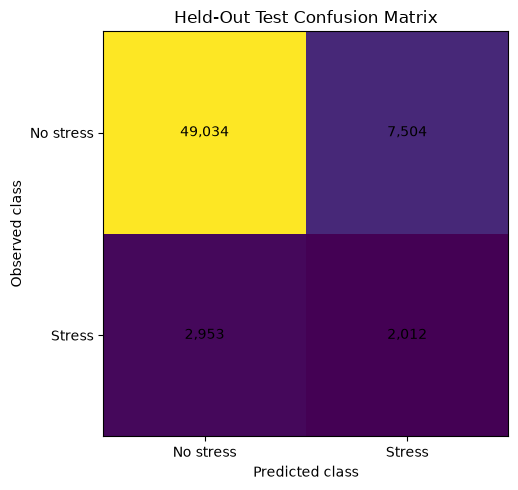

In [8]:

from sklearn.metrics import average_precision_score

test_metrics = {
    "PR-AUC": average_precision_score(
        y_test, stress_probability
    ),
    "ROC-AUC": roc_auc_score(
        y_test, stress_probability
    ),
    "Brier Score": brier_score_loss(
        y_test, stress_probability
    ),
    "Precision at selected threshold": precision_score(
        y_test, stress_prediction, zero_division=0
    ),
    "Recall at selected threshold": recall_score(
        y_test, stress_prediction, zero_division=0
    ),
    "F1 at selected threshold": f1_score(
        y_test, stress_prediction, zero_division=0
    ),
    "Stress prevalence": float(y_test.mean()),
    "Selected threshold": selected_threshold,
}

display(pd.DataFrame(
    list(test_metrics.items()),
    columns=["Metric", "Value"]
))

print(classification_report(
    y_test,
    stress_prediction,
    target_names=["No recorded stress", "Recorded stress"],
    zero_division=0
))

cm = confusion_matrix(y_test, stress_prediction)

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm)
ax.set_title("Held-Out Test Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Observed class")
ax.set_xticks([0, 1], ["No stress", "Stress"])
ax.set_yticks([0, 1], ["No stress", "Stress"])

for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, f"{value:,}", ha="center", va="center")

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

with open(
    REPORT_DIR / "test_performance_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {k: float(v) for k, v in test_metrics.items()},
        file,
        indent=2
    )


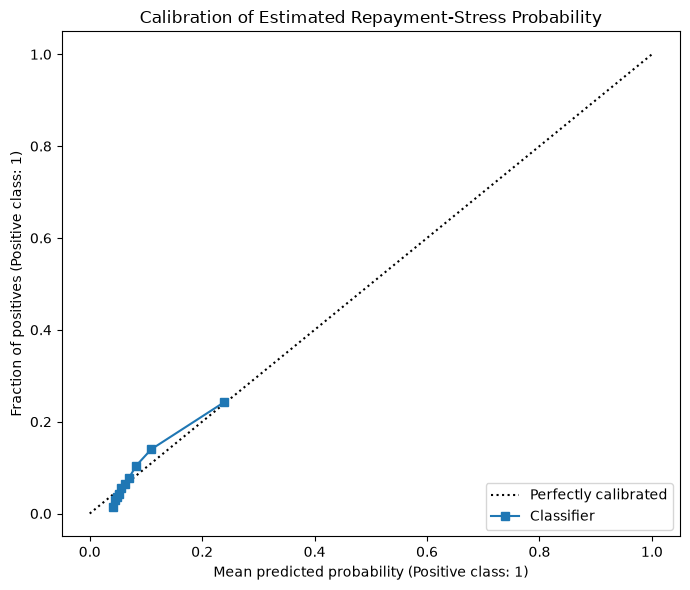

,Mean predicted stress probability,Observed stress prevalence,Absolute difference,Brier score
0,0.080665,0.080728,0.000063,0.070255


In [9]:

fig, ax = plt.subplots(figsize=(7, 6))

CalibrationDisplay.from_predictions(
    y_test,
    stress_probability,
    n_bins=10,
    strategy="quantile",
    ax=ax
)

ax.set_title("Calibration of Estimated Repayment-Stress Probability")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "calibration_curve.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Compare mean predicted probability with observed prevalence.
calibration_summary = pd.DataFrame({
    "Mean predicted stress probability": [stress_probability.mean()],
    "Observed stress prevalence": [y_test.mean()],
    "Absolute difference": [
        abs(stress_probability.mean() - y_test.mean())
    ],
    "Brier score": [brier_score_loss(y_test, stress_probability)],
})

display(calibration_summary)

calibration_summary.to_csv(
    REPORT_DIR / "calibration_summary.csv",
    index=False
)


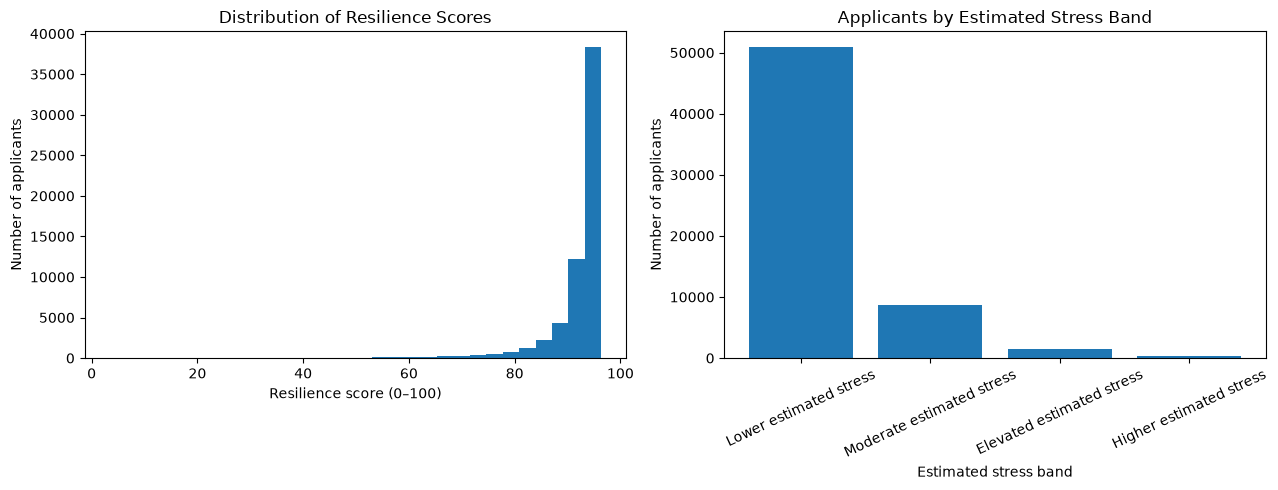

,Risk_Band,Applicants,Mean_Stress_Probability,Mean_Resilience_Score,Observed_Stress_Rate,Applicant_Percentage
0,Lower estimated stress,50942,0.058589,94.141051,0.055318,82.828480
1,Moderate estimated stress,8740,0.144778,85.522167,0.176201,14.210689
2,Elevated estimated stress,1480,0.335049,66.495141,0.312162,2.406387
3,Higher estimated stress,341,0.631205,36.879465,0.425220,0.554444


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    scored_applicants["Resilience_Score"],
    bins=30
)
axes[0].set_title("Distribution of Resilience Scores")
axes[0].set_xlabel("Resilience score (0–100)")
axes[0].set_ylabel("Number of applicants")

risk_order = [
    "Lower estimated stress",
    "Moderate estimated stress",
    "Elevated estimated stress",
    "Higher estimated stress",
]

risk_counts = (
    scored_applicants["Risk_Band"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
)

axes[1].bar(
    risk_counts.index.astype(str),
    risk_counts.values
)
axes[1].set_title("Applicants by Estimated Stress Band")
axes[1].set_xlabel("Estimated stress band")
axes[1].set_ylabel("Number of applicants")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "score_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

risk_summary = (
    scored_applicants.groupby("Risk_Band", observed=False)
    .agg(
        Applicants=(ID_COLUMN, "count"),
        Mean_Stress_Probability=("Stress_Probability", "mean"),
        Mean_Resilience_Score=("Resilience_Score", "mean"),
        Observed_Stress_Rate=("Actual_TARGET", "mean"),
    )
    .reset_index()
)

risk_summary["Applicant_Percentage"] = (
    risk_summary["Applicants"] / len(scored_applicants) * 100
)

display(risk_summary)

risk_summary.to_csv(
    REPORT_DIR / "risk_band_summary.csv",
    index=False
)


,Score_Decile,Applicants,Mean_Stress_Probability,Mean_Resilience_Score,Observed_Stress_Rate
0,1,6151,0.041491,95.850909,0.015282
1,2,6150,0.045194,95.480565,0.029106
2,3,6150,0.048444,95.155618,0.035447
3,4,6150,0.052084,94.791575,0.043089
4,5,6151,0.056380,94.361962,0.055601
5,6,6150,0.061935,93.806541,0.064390
6,7,6150,0.069851,93.014941,0.077724
7,8,6150,0.082780,91.722016,0.104390
8,9,6150,0.109340,89.065964,0.139837
9,10,6151,0.239136,76.086422,0.242400


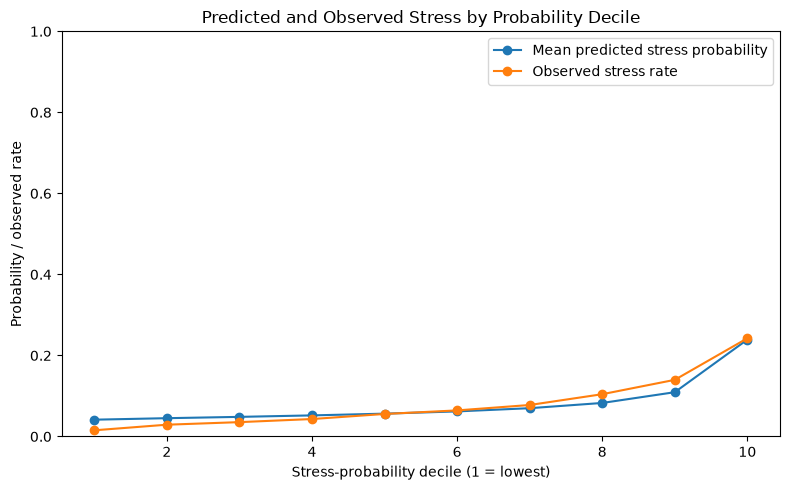

Spearman correlation between mean predicted probability and observed stress rate across deciles: 1.0


In [11]:
scored_applicants["Score_Decile"] = pd.qcut(
    scored_applicants["Stress_Probability"].rank(method="first"),
    q=10,
    labels=False
) + 1

decile_summary = (
    scored_applicants.groupby("Score_Decile")
    .agg(
        Applicants=(ID_COLUMN, "count"),
        Mean_Stress_Probability=("Stress_Probability", "mean"),
        Mean_Resilience_Score=("Resilience_Score", "mean"),
        Observed_Stress_Rate=("Actual_TARGET", "mean"),
    )
    .reset_index()
)

display(decile_summary)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    decile_summary["Score_Decile"],
    decile_summary["Mean_Stress_Probability"],
    marker="o",
    label="Mean predicted stress probability"
)

ax.plot(
    decile_summary["Score_Decile"],
    decile_summary["Observed_Stress_Rate"],
    marker="o",
    label="Observed stress rate"
)

ax.set_title("Predicted and Observed Stress by Probability Decile")
ax.set_xlabel("Stress-probability decile (1 = lowest)")
ax.set_ylabel("Probability / observed rate")
ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "decile_validation.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

decile_summary.to_csv(
    REPORT_DIR / "decile_validation.csv",
    index=False
)

# A descriptive check of score ordering.
decile_spearman = decile_summary[
    ["Mean_Stress_Probability", "Observed_Stress_Rate"]
].corr(method="spearman").iloc[0, 1]

print(
    "Spearman correlation between mean predicted probability "
    "and observed stress rate across deciles:",
    round(float(decile_spearman), 4)
)


In [13]:

audit_path = ARTIFACT_DIR / "home_credit_audit_columns.csv"


if audit_path.exists():
    audit_df = pd.read_csv(audit_path)

    if ID_COLUMN not in audit_df.columns:
        raise ValueError("Audit file does not contain applicant IDs.")

    if audit_df[ID_COLUMN].duplicated().any():
        raise ValueError("Duplicate applicant IDs in audit file.")

    audit_scored = scored_applicants.merge(
        audit_df,
        on=ID_COLUMN,
        how="left",
        validate="one_to_one"
    )

    def calculate_group_metrics(data, group_column, label):
        results = []

        for group_value, group in data.groupby(
            group_column,
            dropna=False,
            observed=False
        ):
            y_group = group["Actual_TARGET"].astype(int)
            pred_group = group["Predicted_Stress"].astype(int)

            negatives = int((y_group == 0).sum())
            false_positives = int(
                ((y_group == 0) & (pred_group == 1)).sum()
            )

            results.append({
                "Attribute": label,
                "Group": str(group_value),
                "Applicants": len(group),
                "Observed stress rate": y_group.mean(),
                "Mean predicted stress probability": (
                    group["Stress_Probability"].mean()
                ),
                "Mean resilience score": (
                    group["Resilience_Score"].mean()
                ),
                "Recall": recall_score(
                    y_group, pred_group, zero_division=0
                ),
                "False positive rate": (
                    false_positives / negatives
                    if negatives else np.nan
                ),
                "Selection rate": pred_group.mean(),
            })

        return pd.DataFrame(results)

    fairness_tables = []

    if "CODE_GENDER" in audit_scored.columns:
        fairness_tables.append(
            calculate_group_metrics(
                audit_scored,
                "CODE_GENDER",
                "Gender"
            )
        )

    if "DAYS_BIRTH" in audit_scored.columns:
        audit_scored["AGE_YEARS"] = (
            -audit_scored["DAYS_BIRTH"] / 365.25
        )

        audit_scored["AGE_BAND"] = pd.cut(
            audit_scored["AGE_YEARS"],
            bins=[0, 25, 35, 45, 55, 120],
            labels=[
                "Under 25", "25-34", "35-44", "45-54", "55+"
            ],
            right=False
        )

        fairness_tables.append(
            calculate_group_metrics(
                audit_scored,
                "AGE_BAND",
                "Age band"
            )
        )

    if fairness_tables:
        fairness_results = pd.concat(
            fairness_tables,
            ignore_index=True
        )

        display(fairness_results)

        fairness_results.to_csv(
            REPORT_DIR / "fairness_subgroup_results.csv",
            index=False
        )
    else:
        print(
            "No supported gender or age audit columns were found. "
            "Fairness results were not produced."
        )
else:
    print(
        "Audit artifact is unavailable. Complete the audit-data preparation "
        "before reporting subgroup fairness."
    )


,Attribute,Group,Applicants,Observed stress rate,Mean predicted stress probability,Mean resilience score,Recall,False positive rate,Selection rate
0,Gender,F,40561,0.069919,0.076505,92.349539,0.375176,0.114805,0.133010
1,Gender,M,20940,0.101671,0.088725,91.127516,0.445279,0.168678,0.196800
2,Gender,XNA,2,0.000000,0.069955,93.004545,0.000000,0.000000,0.000000
3,Age band,Under 25,2392,0.117057,0.115667,88.433281,0.575000,0.328598,0.357441
4,Age band,25-34,14368,0.105303,0.096602,90.339785,0.512227,0.204278,0.236707
5,Age band,35-44,16889,0.082835,0.081691,91.830894,0.411008,0.134926,0.157795
6,Age band,45-54,14039,0.073367,0.076030,92.397002,0.375728,0.112537,0.131847
7,Age band,55+,13815,0.053782,0.061485,93.851461,0.153432,0.048195,0.053855


In [14]:

classifier = None
preprocessor = None

# Retrieve the underlying classifier from the calibrated model.
if hasattr(calibrated_model, "calibrated_classifiers_"):
    fitted_calibrators = calibrated_model.calibrated_classifiers_

    if fitted_calibrators:
        fitted_pipeline = fitted_calibrators[0].estimator

        if hasattr(fitted_pipeline, "named_steps"):
            preprocessor = fitted_pipeline.named_steps.get("preprocessor")
            classifier = fitted_pipeline.named_steps.get("classifier")

importance_df = None

if classifier is not None and preprocessor is not None:
    transformed_names = preprocessor.get_feature_names_out()

    if hasattr(classifier, "feature_importances_"):
        importances = classifier.feature_importances_

        importance_df = pd.DataFrame({
            "Feature": transformed_names,
            "Importance": importances,
        }).sort_values("Importance", ascending=False)

    elif hasattr(classifier, "coef_"):
        coefficients = np.asarray(classifier.coef_).ravel()

        importance_df = pd.DataFrame({
            "Feature": transformed_names,
            "Coefficient": coefficients,
            "Absolute Coefficient": np.abs(coefficients),
        }).sort_values(
            "Absolute Coefficient",
            ascending=False
        )

if importance_df is not None:
    display(importance_df.head(20))

    importance_df.to_csv(
        REPORT_DIR / "global_feature_importance.csv",
        index=False
    )

    value_column = (
        "Importance"
        if "Importance" in importance_df.columns
        else "Absolute Coefficient"
    )

    top_features = importance_df.head(20).sort_values(value_column)

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(
        top_features["Feature"].astype(str),
        top_features[value_column]
    )
    ax.set_title("Top 20 Global Model Features")
    ax.set_xlabel(value_column)
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "global_feature_importance.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
else:
    print(
        "Global importance could not be extracted from the saved calibrated "
        "pipeline. Use the selected base estimator from Notebook 2 and its "
        "compatible SHAP explainer instead of guessing feature importance."
    )


Global importance could not be extracted from the saved calibrated pipeline. Use the selected base estimator from Notebook 2 and its compatible SHAP explainer instead of guessing feature importance.


In [15]:

# Join behavioural features to the held-out scored applicants.
behaviour_columns = [
    c for c in group_b_features
    if c in test_df.columns
]

applicant_profiles = scored_applicants.merge(
    test_df[[ID_COLUMN] + behaviour_columns],
    on=ID_COLUMN,
    how="left",
    validate="one_to_one"
)

def explain_applicant(applicant_id):
    matches = applicant_profiles[
        applicant_profiles[ID_COLUMN] == applicant_id
    ]

    if matches.empty:
        raise KeyError(
            f"Applicant ID {applicant_id} was not found in the scored test set."
        )

    row = matches.iloc[0]

    print("Applicant ID:", row[ID_COLUMN])
    print("Resilience score:", round(row["Resilience_Score"], 2))
    print(
        "Estimated repayment-stress probability:",
        round(row["Stress_Probability"], 4)
    )
    print("Estimated stress band:", row["Risk_Band"])
    print(
        "Predicted stress at selected threshold:",
        int(row["Predicted_Stress"])
    )

    profile = pd.DataFrame({
        "Feature": behaviour_columns,
        "Value": [
            row[c] for c in behaviour_columns
        ]
    })

    profile = profile[
        profile["Value"].notna()
    ].reset_index(drop=True)

    print(
        "\nObserved behavioural features for this applicant "
        "(descriptive, not causal):"
    )
    display(profile.head(20))

    return profile


# Example: explain the first applicant in the held-out scored set.
example_applicant_id = scored_applicants[ID_COLUMN].iloc[0]

example_profile = explain_applicant(example_applicant_id)


Applicant ID: 100009
Resilience score: 95.6
Estimated repayment-stress probability: 0.044
Estimated stress band: Lower estimated stress
Predicted stress at selected threshold: 0

Observed behavioural features for this applicant (descriptive, not causal):


,Feature,Value
0,RATIO_MAX,1.000000e+00
1,LATE_DAYS_MAX,7.000000e+00
2,INST_PAYMENT_RATIO_MEAN,1.000000e+00
3,INST_PAYMENT_RATIO_STD,0.000000e+00
4,INST_UNDERPAID_SHARE,0.000000e+00
5,INST_MEAN_DAYS_LATE,1.372549e-01
6,INST_LATE_PAYMENT_SHARE,1.960784e-02
7,INST_UNDERPAID_SHARE_6M,0.000000e+00
8,INST_UNDERPAID_SHARE_12M,0.000000e+00
9,HAS_INSTALLMENT_HISTORY,1.000000e+00


In [16]:
score_export_columns = [
    ID_COLUMN,
    "Stress_Probability",
    "Resilience_Score",
    "Predicted_Stress",
    "Risk_Band",
    "Decision_Threshold",
    "Actual_TARGET",
]

final_score_table = scored_applicants[score_export_columns].copy()

# Save the labelled held-out evaluation file separately.
final_score_table.to_csv(
    REPORT_DIR / "home_credit_resilience_scores_test.csv",
    index=False
)

final_score_table.drop(
    columns=["Actual_TARGET"]
).to_csv(
    REPORT_DIR / "home_credit_resilience_scores_unlabelled.csv",
    index=False
)

final_score_table.to_parquet(
    REPORT_DIR / "home_credit_resilience_scores_test.parquet",
    index=False
)

print("Score exports saved:")
print(REPORT_DIR / "home_credit_resilience_scores_test.csv")
print(REPORT_DIR / "home_credit_resilience_scores_unlabelled.csv")
print(REPORT_DIR / "home_credit_resilience_scores_test.parquet")

display(final_score_table.head(10))


Score exports saved:
c:\mini_project\results\final_report\home_credit_resilience_scores_test.csv
c:\mini_project\results\final_report\home_credit_resilience_scores_unlabelled.csv
c:\mini_project\results\final_report\home_credit_resilience_scores_test.parquet


,SK_ID_CURR,Stress_Probability,Resilience_Score,Predicted_Stress,Risk_Band,Decision_Threshold,Actual_TARGET
0,100009,0.043962,95.603844,0,Lower estimated stress,0.105875,0
1,100014,0.061273,93.872687,0,Lower estimated stress,0.105875,0
2,100015,0.050980,94.902004,0,Lower estimated stress,0.105875,0
3,100018,0.059979,94.002079,0,Lower estimated stress,0.105875,0
4,100020,0.177267,82.273346,1,Moderate estimated stress,0.105875,0
5,100023,0.044032,95.596807,0,Lower estimated stress,0.105875,0
6,100024,0.051042,94.895816,0,Lower estimated stress,0.105875,0
7,100045,0.051276,94.872445,0,Lower estimated stress,0.105875,0
8,100046,0.039251,96.074896,0,Lower estimated stress,0.105875,0
9,100051,0.141700,85.829991,1,Moderate estimated stress,0.105875,0


In [17]:
score_summary = {
    "project": "FinResilience AI",
    "score_definition": "100 * (1 - calibrated stress probability)",
    "target": TARGET,
    "threshold": selected_threshold,
    "scored_applicants": int(len(scored_applicants)),
    "mean_resilience_score": float(
        scored_applicants["Resilience_Score"].mean()
    ),
    "median_resilience_score": float(
        scored_applicants["Resilience_Score"].median()
    ),
    "mean_stress_probability": float(
        scored_applicants["Stress_Probability"].mean()
    ),
    "observed_stress_rate": float(y_test.mean()),
    "pr_auc": float(test_metrics["PR-AUC"]),
    "roc_auc": float(test_metrics["ROC-AUC"]),
    "brier_score": float(test_metrics["Brier Score"]),
    "precision": float(
        test_metrics["Precision at selected threshold"]
    ),
    "recall": float(
        test_metrics["Recall at selected threshold"]
    ),
    "f1": float(
        test_metrics["F1 at selected threshold"]
    ),
    "risk_band_counts": {
        str(k): int(v)
        for k, v in scored_applicants["Risk_Band"]
        .value_counts(dropna=False)
        .items()
    },
    "test_partition_used_for_model_tuning": False,
    "test_partition_used_for_threshold_selection": False,
}

with open(
    REPORT_DIR / "final_validation_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(score_summary, file, indent=2)

print(json.dumps(score_summary, indent=2))


{
  "project": "FinResilience AI",
  "score_definition": "100 * (1 - calibrated stress probability)",
  "target": "TARGET",
  "threshold": 0.10587531123103444,
  "scored_applicants": 61503,
  "mean_resilience_score": 91.93349673002936,
  "median_resilience_score": 94.11436676101403,
  "mean_stress_probability": 0.0806650326997064,
  "observed_stress_rate": 0.08072776937710356,
  "pr_auc": 0.20622236019637097,
  "roc_auc": 0.7249578953341971,
  "brier_score": 0.07025504261309277,
  "precision": 0.2114333753678016,
  "recall": 0.4052366565961732,
  "f1": 0.27788136178440714,
  "risk_band_counts": {
    "Lower estimated stress": 50942,
    "Moderate estimated stress": 8740,
    "Elevated estimated stress": 1480,
    "Higher estimated stress": 341
  },
  "test_partition_used_for_model_tuning": false,
  "test_partition_used_for_threshold_selection": false
}


In [18]:
readiness_checks = {
    "Required model and test artifacts exist": all(
        p.exists() for p in REQUIRED_ARTIFACTS
    ),
    "All applicants have unique IDs": (
        scored_applicants[ID_COLUMN].is_unique
    ),
    "All scores are within 0-100": (
        scored_applicants["Resilience_Score"].between(0, 100).all()
    ),
    "All probabilities are within 0-1": (
        scored_applicants["Stress_Probability"].between(0, 1).all()
    ),
    "No missing probabilities": (
        scored_applicants["Stress_Probability"].notna().all()
    ),
    "No missing resilience scores": (
        scored_applicants["Resilience_Score"].notna().all()
    ),
    "Prediction threshold applied consistently": (
        (
            scored_applicants["Predicted_Stress"]
            == (
                scored_applicants["Stress_Probability"]
                >= selected_threshold
            ).astype(int)
        ).all()
    ),
    "Final score table saved": (
        REPORT_DIR / "home_credit_resilience_scores_test.csv"
    ).exists(),
    "Validation summary saved": (
        REPORT_DIR / "final_validation_summary.json"
    ).exists(),
}

readiness_df = pd.DataFrame(
    [
        {"Check": name, "Passed": bool(passed)}
        for name, passed in readiness_checks.items()
    ]
)

display(readiness_df)

if not readiness_df["Passed"].all():
    print("Some readiness checks failed. Resolve them before proceeding.")
else:
    print("Basic scoring and export checks passed.")

print("\nResearch limitations to document:")
print("1. The score estimates the dataset's defined repayment-stress target.")
print("2. It does not measure every dimension of financial resilience.")
print("3. Results are limited by the dataset population and recorded features.")
print("4. Group differences require careful fairness interpretation.")
print("5. Predictive associations and explanations are not causal effects.")
print("6. Verify historical-feature availability before claiming leakage safety.")
print("\nNotebook 3 finished.")


,Check,Passed
0,Required model and test artifacts exist,True
1,All applicants have unique IDs,True
2,All scores are within 0-100,True
3,All probabilities are within 0-1,True
4,No missing probabilities,True
5,No missing resilience scores,True
6,Prediction threshold applied consistently,True
7,Final score table saved,True
8,Validation summary saved,True


Basic scoring and export checks passed.

Research limitations to document:
1. The score estimates the dataset's defined repayment-stress target.
2. It does not measure every dimension of financial resilience.
3. Results are limited by the dataset population and recorded features.
4. Group differences require careful fairness interpretation.
5. Predictive associations and explanations are not causal effects.
6. Verify historical-feature availability before claiming leakage safety.

Notebook 3 finished.
